# Three settings: swing and mean pressure, full simulation against the averaged model

The averaged model of `outlet_temperature_check.ipynb` (same code, same constants), with the outflow carrying either the cycle-mean temperature $\bar T$ or the one-point temperature $T_{out} = \bar T (P^*/\bar P)^{\varepsilon}$, $P^* = P_{out} + \Delta P_{max}/3$ (the CV temperature at the pressure where the outlet reed passes the most gas), against the full simulation reduced to per-cycle values. Three settings of the sweep notebook:

1. **baseline** (5 m/s kick): grows to a steady oscillation;
2. **2.5 m/s kick**: grows, turns over and stalls — the close race, where the two treatments differ most;
3. **$V_{0p} = 10^{-4}$ m$^3$**: stalls.

The figure is `fig_outlet_temperature_cases_Tout.pdf` / `.png`, Figure 1 of the $T_{out}$ version of the write-up.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
MODE_COL = {'Tbar': INK2, 'Tout': ORANGE, 'exact': BLUE}
MODE_LAB = {'Tbar': 'T_bar (current)', 'Tout': 'T_out at P* (one point)', 'exact': 'adiabatic T(psi) in the integrals'}

BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4)
MODES = ('Tbar', 'Tout', 'exact')


class Model:
    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.eps = self.R / (self.cv + self.R)
        self.Pstar = self.P_out + self.dP_max / 3.0
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI)

    # ---------- valve law ----------
    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); mr = dP <= 0
        out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo]); out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    def slope(self, dP, h=1.0):
        return (self.reed(dP + h) - self.reed(dP - h)) / (2 * h)

    # ---------- full model (unchanged: the outflow carries the actual CV temperature) ----------
    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def run_full(self, t_end, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Full model in chunks; once the oscillation is dead and the mean has landed on P_in or P_out (a stiff, expensive
        tail for the solver), the rest of the run is filled with the frozen state."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        y = [self.x0, self.v0, M0, self.cv * M0 * self.T0]; ts, Ps, Ts = [], [], []; t0 = 0.0
        while t0 < t_end - 1e-9:
            t1 = min(t0 + chunk, t_end)
            te = np.append(np.arange(t0, t1, 1.0 / fs), t1)            # last entry = chunk end, used only to restart
            sol = solve_ivp(self.full_ode, (t0, t1), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            x, v, M, E = sol.y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
            ts.append(sol.t[:-1]); Ps.append(P[:-1]); Ts.append(T[:-1]); y = sol.y[:, -1]; t0 = t1
            tail = sol.t > t1 - 0.05
            landed = min(np.abs(P[tail] - self.P_in).max(), np.abs(P[tail] - self.P_out).max()) < 20.0
            if landed and np.abs(v[tail]).max() < 1e-3:
                tr = np.arange(t1, t_end, 1.0 / fs)
                ts.append(tr); Ps.append(np.full(tr.size, P[-1])); Ts.append(np.full(tr.size, T[-1])); break
        return np.concatenate(ts), np.concatenate(Ps), np.concatenate(Ts)

    # ---------- averaged model ----------
    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def inlet(self, Pb, delta):
        """Inlet mean flow and gain (own-drop convention, as in the notebooks): F0_in and F1_in/delta."""
        if delta > 1.0:
            vals = self.reed_vec(self.P_in - Pb + delta * self.CPS)
            return vals.mean(), 2.0 * (vals * self.CPS).mean() / delta
        return self.reed(self.P_in - Pb), self.slope(self.P_in - Pb)

    def outlet(self, Pb, Tb, delta, mode):
        """Outlet mean mass flow F0_out, mean enthalpy-carrying flux H0 (= <mdot_out T>), and gain G (= H1/delta)."""
        if delta > 1.0:
            P = Pb + delta * self.CPS; vals = self.reed_vec(P - self.P_out); F0 = vals.mean()
            if mode == 'exact':
                T = Tb * (P / Pb) ** self.eps
                return F0, (vals * T).mean(), 2.0 * (vals * T * self.CPS).mean() / delta
            Tw = Tb if mode == 'Tbar' else Tb * (self.Pstar / Pb) ** self.eps
            return F0, Tw * F0, Tw * 2.0 * (vals * self.CPS).mean() / delta
        F0 = self.reed(Pb - self.P_out); s = self.slope(Pb - self.P_out)
        if mode == 'exact':                                   # small swing: T' = eps T_bar P'/P_bar rides on the mean flow
            return F0, Tb * F0, Tb * s + F0 * self.eps * Tb / Pb
        Tw = Tb if mode == 'Tbar' else Tb * (self.Pstar / Pb) ** self.eps
        return F0, Tw * F0, Tw * s

    def rates(self, Pb, Tb, delta, mode):
        Vp, Vc, kcv, kp, w = self.geom(Pb)
        F0i, Ni = self.inlet(Pb, delta); F0o, H0o, Go = self.outlet(Pb, Tb, delta, mode)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Go)
        lam = -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)
        dMb = F0i - F0o
        dPb = (self.Cf * (self.T_in * F0i - H0o) - Vc * g * delta ** 2 / (2 * Pb)) / (Vc + (self.gamma_E / self.gamma) * Vp)
        return lam, g, dMb, dPb, w

    def slow_rhs(self, t, y, mode):
        Mb, Pb, a = y; a = max(a, 0.0)
        Vp, Vc, kcv, kp, w = self.geom(Pb); Tb = Pb * Vc / (Mb * self.R); delta = kcv * a / self.A_neck
        lam, g, dMb, dPb, w = self.rates(Pb, Tb, delta, mode)
        dPp = 1e-4 * max(abs(dPb), 1.0); wdot = (self.geom(Pb + dPp)[4] - w) / dPp * dPb
        da = lam * a - (wdot / (2 * w)) * a
        if a <= 1e-10 and da < 0:
            da = 0.0
        return [dMb, dPb, da]

    def run_avg(self, t_end, mode, chunk=0.25):
        """Slow ODEs in chunks; stops once the amplitude has died (delta below 10 Pa) and the mean has landed within 50 Pa
        of P_in or P_out, where the square-root valve law makes the tail stiff; after that the state is frozen."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0); w0 = self.geom(self.P0)[4]
        y = [M0, self.P0, self.v0 / w0]; t0 = 0.0; sols = []

        def landed(t, yy):
            Mb, Pb, a = yy
            if self.geom(Pb)[2] * max(a, 0.0) / self.A_neck > 10.0:
                return 1e3
            return min(self.P_in - Pb, Pb - self.P_out) - 50.0
        landed.terminal = True; landed.direction = -1
        while t0 < t_end - 1e-9:
            t1 = min(t0 + chunk, t_end)
            sol = solve_ivp(lambda t, yy: self.slow_rhs(t, yy, mode), (t0, t1), y, method='LSODA', events=landed,
                            rtol=1e-8, atol=[1e-12, 1e-3, 1e-11], dense_output=True, max_step=min(2e-3, t_end / 2000))
            sols.append(sol); y = sol.y[:, -1]; t0 = sol.t[-1]
            if sol.status == 1:
                break
        return AvgSol(sols, y)

    def observe(self, sol, ta):
        Mb, Pb, a = sol.sol(ta)
        kcv = np.array([self.geom(p)[2] for p in Pb])
        return Pb, kcv * np.maximum(a, 0) / self.A_neck

    # ---------- e-fold budget with the variant's outlet temperature ----------
    def fill_budget(self, mode, t_end=8.0):
        """Slow equations with no oscillation (delta = 0) and the variant's outlet temperature; B = integral of lambda_lin
        up to its first zero.  Returns (B, t_1, no_window)."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)

        def lam_lin(Mb, Pb):
            Vc = self.geom(Pb)[1]; Tb = Pb * Vc / (Mb * self.R)
            return self.rates(Pb, Tb, 0.0, mode)[0]

        def rhs(t, y):
            Mb, Pb = y; Vc = self.geom(Pb)[1]; Tb = Pb * Vc / (Mb * self.R)
            _, _, dMb, dPb, _ = self.rates(Pb, Tb, 0.0, mode)
            return [dMb, dPb]

        def stop(t, y):
            return lam_lin(*y)
        stop.terminal = True; stop.direction = -1
        if lam_lin(M0, self.P0) < 0:
            return 0.0, 0.0, True
        sol = solve_ivp(rhs, (0.0, t_end), [M0, self.P0], method='LSODA', rtol=1e-7, atol=[1e-12, 1e-3],
                        dense_output=True, events=stop, max_step=5e-3)
        t1 = sol.t_events[0][0] if len(sol.t_events[0]) else sol.t[-1]
        ta = np.linspace(0.0, t1, 2001); Mb, Pb = sol.sol(ta)
        ll = np.array([lam_lin(Mb[i], Pb[i]) for i in range(len(ta))])
        return float(np.sum(0.5 * (ll[1:] + ll[:-1]) * np.diff(ta))), float(t1), False

    def delta0(self):
        Vp, Vc, kcv, kp, w0 = self.geom(self.P0)
        return kcv * self.v0 / (w0 * self.A_neck)


class AvgSol:
    """Dense output over the chunks; after the last chunk the state is frozen."""

    def __init__(self, sols, y_last):
        self.sols = sols; self.y_last = np.asarray(y_last); self.t_last = sols[-1].t[-1]

    def sol(self, ta):
        ta = np.atleast_1d(np.asarray(ta, dtype=float)); out = np.empty((3, ta.size))
        for j, tt in enumerate(ta):
            if tt >= self.t_last:
                out[:, j] = self.y_last
                continue
            for s_ in self.sols:
                if s_.t[0] <= tt <= s_.t[-1]:
                    out[:, j] = s_.sol(tt); break
        return out if out.shape[1] > 1 else out[:, 0]


def per_cycle(model, t, P, T):
    """Per-cycle mean pressure, half swing, mean temperature, and the temperature carried by the outflow
    (<mdot_out T>/<mdot_out> over the cycle, backflow included as in the model's energy equation)."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    mo = model.reed_vec(P - model.P_out)
    rows = []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        F = mo[m].mean()
        rows.append((0.5 * (a + b), P[m].mean(), 0.5 * (P[m].max() - P[m].min()), T[m].mean(),
                     (mo[m] * T[m]).mean() / F if abs(F) > 1e-7 else np.nan))
    return [np.array(c) for c in zip(*rows)]


SWEEPS = {
    'm_max':   ('valve capacity  mdot_max [kg/s]',   [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed bias factor  zeta',             [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping  b [N s/m]',          [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume  V0_pass [m^3]',      [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass  m [kg]',                [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick  v0 [m/s]',             [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure  P_in [Pa]',          [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}


def t_end_for(model):
    Mtot = model.P0 * (model.V0_cv + model.V0_pass) / (model.R * model.T0)
    return float(np.clip(1.5 * Mtot / model.m_max, 1.0, 6.0))

baseline: 5 m/s kick, steady oscillation      [6 s]


2.5 m/s kick: grows, turns over, stalls       [10 s]


$V_{0p} = 10^{-4}$ m$^3$: stalls              [14 s]


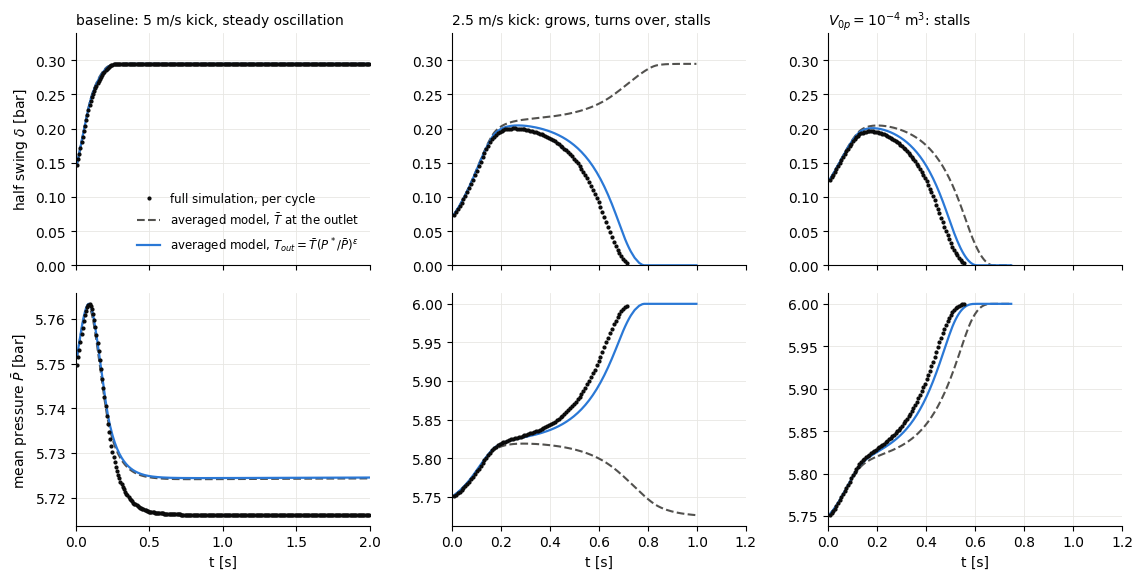

baseline: 5 m/s kick, steady oscillation      mean pressure error on the plateau: T_bar +7.9 mbar, T_out +8.2 mbar;  envelope error over the run (rms, % of the largest swing): T_bar 0.3, T_out 0.3
2.5 m/s kick: grows, turns over, stalls       mean pressure error on the plateau: T_bar -13.3 mbar, T_out -3.2 mbar;  envelope error over the run (rms, % of the largest swing): T_bar 100.6, T_out 8.5
$V_{0p} = 10^{-4}$ m$^3$: stalls              mean pressure error on the plateau: T_bar -10.8 mbar, T_out -4.6 mbar;  envelope error over the run (rms, % of the largest swing): T_bar 19.2, T_out 6.5


In [2]:
CASES = [(dict(), 'baseline: 5 m/s kick, steady oscillation'),
         (dict(v0=2.5), '2.5 m/s kick: grows, turns over, stalls'),
         (dict(V0_pass=1e-4), r'$V_{0p} = 10^{-4}$ m$^3$: stalls')]
tic = time.time(); runs = []
for kw, title in CASES:
    m = Model(**kw); te = min(t_end_for(m), 2.0)
    t, P, T = m.run_full(te); tm, Pm, half, Tm, Tflow = per_cycle(m, t, P, T)
    out = dict(title=title, tm=tm, Pm=Pm, half=half, te=te)
    for mode in ('Tbar', 'Tout'):
        sol = m.run_avg(te, mode); Mb, Pb, a = sol.sol(tm)
        kcv = np.array([m.geom(p)[2] for p in Pb]); out[mode] = dict(Pb=Pb, d=kcv * np.maximum(a, 0) / m.A_neck)
    runs.append(out); print('%-45s [%.0f s]' % (title, time.time() - tic), flush=True)

fig, axs = plt.subplots(2, 3, figsize=(13.5, 6.4), sharex='col'); fig.subplots_adjust(wspace=0.28, hspace=0.12)
for j, r in enumerate(runs):
    live = r['half'] > 300.0
    ax = axs[0, j]
    ax.plot(r['tm'][live], r['half'][live] / 1e5, 'o', ms=2.0, color=INK, label='full simulation, per cycle', zorder=3)
    ax.plot(r['tm'], r['Tbar']['d'] / 1e5, '--', lw=1.5, color=INK2, label=r'averaged model, $\bar T$ at the outlet')
    ax.plot(r['tm'], r['Tout']['d'] / 1e5, '-', lw=1.6, color=BLUE, label=r'averaged model, $T_{out} = \bar T (P^*/\bar P)^{\varepsilon}$')
    ax.set_ylim(0, 0.34); ax.set_title(r['title'], fontsize=10, loc='left')
    ax = axs[1, j]
    ax.plot(r['tm'][live], r['Pm'][live] / 1e5, 'o', ms=2.0, color=INK, zorder=3)
    ax.plot(r['tm'], r['Tbar']['Pb'] / 1e5, '--', lw=1.5, color=INK2)
    ax.plot(r['tm'], r['Tout']['Pb'] / 1e5, '-', lw=1.6, color=BLUE)
    ax.set_xlabel('t [s]'); ax.set_xlim(0, r['te'] if j == 0 else 1.2)
    for ax in axs[:, j]:
        for sp in ['top', 'right']:
            ax.spines[sp].set_visible(False)
        ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
axs[0, 0].set_ylabel('half swing $\\delta$ [bar]'); axs[1, 0].set_ylabel('mean pressure $\\bar P$ [bar]')
axs[0, 0].legend(frameon=False, fontsize=8.5, loc='lower right')
for ext in ('pdf', 'png'):
    fig.savefig('fig_outlet_temperature_cases_Tout.' + ext, dpi=150, bbox_inches='tight')
plt.show()

for r in runs:
    pl = r['half'] > 0.5 * r['half'].max()
    print('%-45s mean pressure error on the plateau: T_bar %+.1f mbar, T_out %+.1f mbar;  envelope error over the run (rms, %% of the largest swing): T_bar %.1f, T_out %.1f'
          % (r['title'][:45], np.median(r['Tbar']['Pb'][pl] - r['Pm'][pl]) / 100, np.median(r['Tout']['Pb'][pl] - r['Pm'][pl]) / 100,
             100 * np.sqrt(np.mean((r['Tbar']['d'] - r['half']) ** 2)) / r['half'].max(), 100 * np.sqrt(np.mean((r['Tout']['d'] - r['half']) ** 2)) / r['half'].max()))